In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split

# Görselleştirme ayarları
sns.set_style("whitegrid")
import warnings
warnings.filterwarnings('ignore')

# 1. VERİYİ YÜKLE
# ========================================================
# Model eğitimi dosyanızda kullandığınız son işlenmiş veriyi yüklüyoruz.
# Dosya adınızın 'processed_used_cars_ready_for_model.csv' veya loglu versiyonu olduğundan emin olun.
csv_path = 'processed_used_cars_ready_for_model.csv' 

try:
    df = pd.read_csv(csv_path)
    print(f"Veri seti başarıyla yüklendi: {df.shape}")
except FileNotFoundError:
    print("HATA: Dosya bulunamadı. Lütfen dosya yolunu kontrol edin.")

Veri seti başarıyla yüklendi: (3885, 37)


In [2]:
# 2. VERİYİ HAZIRLA (TRAIN/TEST SPLIT)
# ========================================================
# Fiyat sütunu hedefimiz.
# Eğer fiyat logaritmik ise (önceki notebokta log_transform yaptıysanız) XAI yorumlarken dikkat edeceğiz.
X = df.drop(['price'], axis=1, errors='ignore')
y = df['price']

# Eğitim ve Test setine ayır (Model eğitimi dosyanızdakiyle aynı random_state'i kullanalım)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print("Veri setleri ayrıldı.")

Veri setleri ayrıldı.


Random Forest modeli eğitiliyor (Bu model SHAP ile tam uyumludur)...
Model eğitimi tamamlandı.
SHAP değerleri hesaplanıyor...
SHAP hesaplaması BAŞARILI!


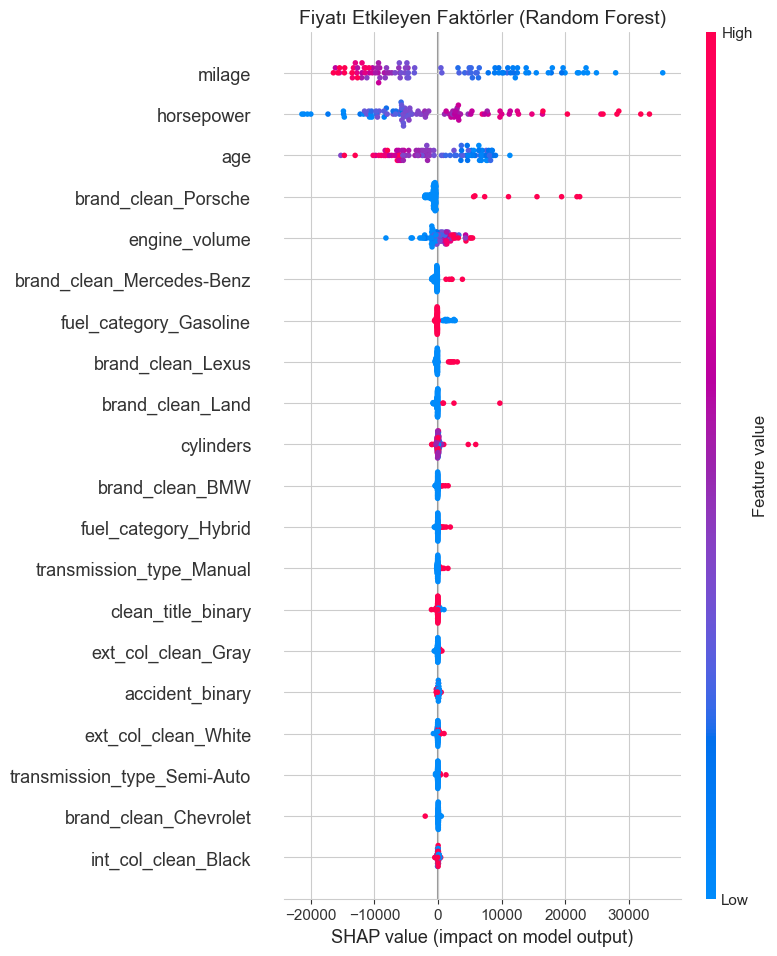

In [6]:
from sklearn.ensemble import RandomForestRegressor
import shap

# 1. Random Forest Modelini Eğit
print("Random Forest modeli eğitiliyor (Bu model SHAP ile tam uyumludur)...")
rf_model = RandomForestRegressor(n_estimators=100, max_depth=20, random_state=42)
rf_model.fit(X_train, y_train)
print("Model eğitimi tamamlandı.")

# 2. SHAP Analizi
print("SHAP değerleri hesaplanıyor...")
explainer = shap.TreeExplainer(rf_model)

# Performans için test setinden sadece 100 örnek alalım (Tüm veri yavaş olabilir)
X_sample = X_test.sample(100, random_state=42)
shap_values = explainer.shap_values(X_sample)

print("SHAP hesaplaması BAŞARILI!")

# 3. Görselleştirme
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_sample, show=False)
plt.title("Fiyatı Etkileyen Faktörler (Random Forest)", fontsize=14)
plt.show()

Random Forest modeli eğitiliyor (Lütfen bekleyiniz)...
Model eğitimi tamamlandı.

--- SEÇİLEN ARAÇ İÇİN TAHMİN RAPORU ---
Gerçek Fiyat       : $8,550
Modelin Tahmini    : $11,300
Fark (Hata)        : $2,750
----------------------------------------
SHAP analizi hazırlanıyor...


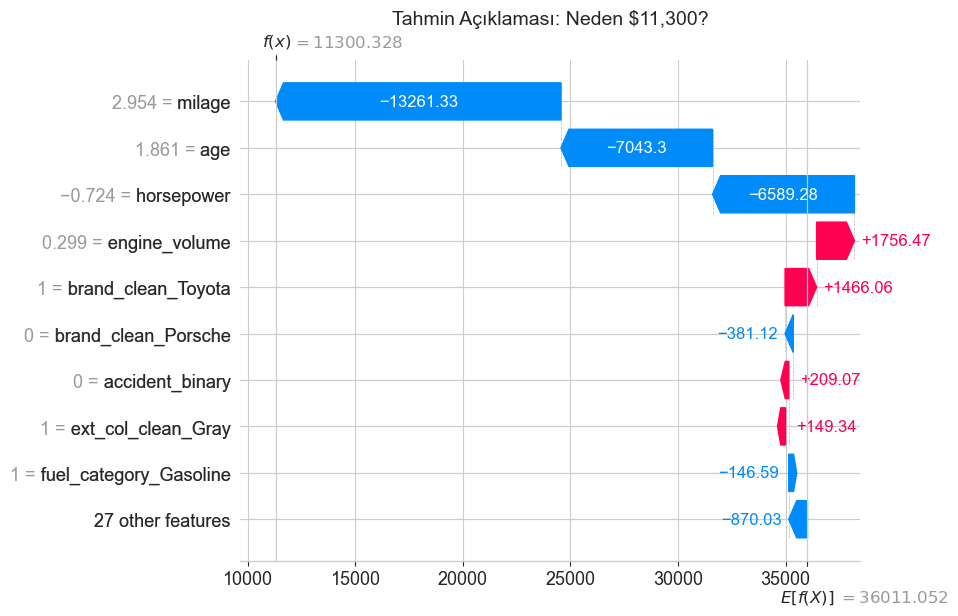

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

# 1. VERİYİ HAZIRLA
# ========================================================
# İşlenmiş veriyi yüklüyoruz
csv_path = 'processed_used_cars_ready_for_model.csv'
df = pd.read_csv(csv_path)

X = df.drop(['price'], axis=1, errors='ignore')
y = df['price']

# Eğitim ve Test ayrımı
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# 2. RANDOM FOREST MODELİNİ EĞİT
# ========================================================
print("Random Forest modeli eğitiliyor (Lütfen bekleyiniz)...")

rf_model = RandomForestRegressor(
    n_estimators=100,  # 100 adet karar ağacı
    max_depth=20,      # Ağaç derinliği
    random_state=42,
    n_jobs=-1          # Tüm işlemcileri kullan
)

rf_model.fit(X_train, y_train)
print("Model eğitimi tamamlandı.")

# 3. RASTGELE BİR ARAÇ SEÇ VE TAHMİN YAP
# ========================================================
# Test setinden rastgele bir araç seçelim (Örn: 5. sıradaki araç)
# Farklı araçlar denemek için buradaki sayıyı değiştirebilirsiniz (0, 10, 50 vb.)
secilen_index = 5 

secilen_arac_verisi = X_test.iloc[[secilen_index]]
gercek_fiyat = y_test.iloc[secilen_index]
tahmin_edilen_fiyat = rf_model.predict(secilen_arac_verisi)[0]

print(f"\n--- SEÇİLEN ARAÇ İÇİN TAHMİN RAPORU ---")
print(f"Gerçek Fiyat       : ${gercek_fiyat:,.0f}")
print(f"Modelin Tahmini    : ${tahmin_edilen_fiyat:,.0f}")
print(f"Fark (Hata)        : ${tahmin_edilen_fiyat - gercek_fiyat:,.0f}")
print("-" * 40)

# 4. NEDEN BU FİYAT? (SHAP WATERFALL ANALİZİ)
# ========================================================
print("SHAP analizi hazırlanıyor...")

# Random Forest için Explainer oluştur
explainer = shap.TreeExplainer(rf_model)

# Sadece seçilen araç için SHAP değerlerini hesapla
shap_values_single = explainer(secilen_arac_verisi)

# GRAFİK ÇİZİMİ (Waterfall)
plt.figure(figsize=(10, 6))
shap.plots.waterfall(shap_values_single[0], show=False)

# Başlık ekle
plt.title(f"Tahmin Açıklaması: Neden ${tahmin_edilen_fiyat:,.0f}?", fontsize=14)
plt.show()

Çıkan Grafik Nasıl Okunur?Bu grafik (Waterfall Plot), 
modelin karar verme hikayesini anlatır:$E[f(X)]$ (Alt Kısım): Bu, modelinizin gördüğü ortalama araba fiyatıdır (Başlangıç noktası). 

Örneğin: $35,000.Kırmızı Barlar (Pozitif Etki): Fiyatı yukarı çeken özelliklerdir.Örnek: model_year (Model Yılı) 2022 ise, bu özellik fiyatı +$10,000 artırmış olabilir.Mavi Barlar (Negatif Etki): Fiyatı aşağı çeken özelliklerdir.Örnek: milage (Kilometre) yüksekse veya 

accident (Kaza) varsa, fiyatı -$5,000 düşürmüş olabilir.$f(x)$ (Üst Kısım): Tüm artış ve azalışların sonucunda modelin ulaştığı son tahmin fiyatıdır.Bu analiz, projenizi sunarken "Modelimiz sadece tahmin yapmıyor, nedenini de biliyor" demenizi sağlayan en güçlü kanıttır.